# Détection des défauts sur les cartes PCB avec YOLO11

**Projet de vision par ordinateur — Notebook d'expérimentation**

**Objectif.** Dans ce travail, je cherche à localiser et à identifier six catégories de défauts visibles sur des images de cartes électroniques. Je pars du dataset *PCB Defects* disponible sur Kaggle et j'adapte un modèle YOLO11 pré-entraîné.

Je commence par vérifier les données et les annotations. Ensuite, j'entraîne un premier modèle, j'analyse ses performances et j'étudie l'effet du flou et des changements de luminosité. Une comparaison facultative avec YOLO11s permet de voir si un modèle plus grand apporte réellement un gain.

**Limite du dataset :** les défauts de ce jeu ont été créés artificiellement. Les résultats ne prouvent donc pas, à eux seuls, que le système fonctionne dans une chaîne d'inspection industrielle.

**Version corrigée pour Google Colab.** Les corrections (taille d'image, séparation par carte, arrêt anticipé, scores par classe, test de robustesse) sont expliquées dans `README.md`.

**À remplir après exécution :** Nom : … | Encadrant : … | Date : …

## 1. Préparer l'environnement

Je travaille sur **Google Colab** avec un GPU : menu **Exécution > Modifier le type d'exécution > GPU T4**. Le dataset `akhatova/pcb-defects` est téléchargé automatiquement depuis Kaggle à l'étape 2. Je fixe une graine aléatoire pour rendre les expériences plus reproductibles.

In [1]:
%pip -q install ultralytics kagglehub

In [2]:
import os, re, random, shutil, hashlib, json, warnings, itertools
from pathlib import Path
from collections import Counter, defaultdict
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
from PIL import Image
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('PyTorch :', torch.__version__)
print('GPU disponible :', torch.cuda.is_available())
print('GPU :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
if not torch.cuda.is_available():
    print('⚠️ Pas de GPU : Exécution > Modifier le type d’exécution > GPU T4. Sans GPU, l’entraînement sera très lent.')
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# Paramètres principaux (voir README.md pour les raisons de ces valeurs)
WORK = Path('/content')
RUNS = WORK/'pcb_runs'
IMGSZ = 1280     # 640 rendait les petits défauts presque invisibles
BATCH = 8        # passer à 4 en cas d'erreur « CUDA out of memory »
EPOCHS = 80
PATIENCE = 0     # 0 = pas d'arrêt anticipé ; best.pt garde quand même la meilleure époque

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch : 2.11.0+cu130
GPU disponible : True
GPU : Tesla T4


## 2. Télécharger et repérer les images et les annotations

Le dataset est téléchargé avec `kagglehub`. Si Kaggle demande une connexion, créer un jeton sur kaggle.com (**Settings > API > Create New Token**) et l'ajouter dans les secrets Colab (icône 🔑) sous les noms `KAGGLE_USERNAME` et `KAGGLE_KEY`, ou exécuter `kagglehub.login()` dans une cellule.

Avant de convertir les données, j'affiche leur structure. Cette vérification évite de supposer que les fichiers XML et les images portent toujours le même chemin.

In [3]:
import kagglehub
try:
    download_dir = Path(kagglehub.dataset_download('akhatova/pcb-defects'))
except Exception as err:
    raise RuntimeError('Téléchargement impossible : ajouter KAGGLE_USERNAME et KAGGLE_KEY '
                       'dans les secrets Colab, ou exécuter kagglehub.login().') from err
found = [p for p in download_dir.rglob('PCB_DATASET') if p.is_dir()]
if not found:
    raise FileNotFoundError(f'Dossier PCB_DATASET introuvable dans {download_dir}.')
DATA_ROOT = found[0].parent
print('Dataset utilisé :', DATA_ROOT)
image_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
images = sorted(p for p in DATA_ROOT.rglob('*') if p.suffix.lower() in image_ext)
xml_files = sorted(DATA_ROOT.rglob('*.xml'))
print('Images trouvées :', len(images), '| Annotations XML :', len(xml_files))
print('Quelques fichiers :')
for p in list(DATA_ROOT.rglob('*'))[:20]:
    print(' -', p.relative_to(DATA_ROOT))
if not xml_files:
    raise RuntimeError('Pas de fichiers XML trouvés : vérifier la version du dataset téléchargé.')

Using Colab cache for faster access to the 'pcb-defects' dataset.
Dataset utilisé : /kaggle/input/pcb-defects
Images trouvées : 1396 | Annotations XML : 693
Quelques fichiers :
 - PCB_DATASET
 - PCB_DATASET/rotate.py
 - PCB_DATASET/PCB_USED
 - PCB_DATASET/Annotations
 - PCB_DATASET/images
 - PCB_DATASET/rotation
 - PCB_DATASET/PCB_USED/10.JPG
 - PCB_DATASET/PCB_USED/01.JPG
 - PCB_DATASET/PCB_USED/09.JPG
 - PCB_DATASET/PCB_USED/05.JPG
 - PCB_DATASET/PCB_USED/06.JPG
 - PCB_DATASET/PCB_USED/04.JPG
 - PCB_DATASET/PCB_USED/12.JPG
 - PCB_DATASET/PCB_USED/11.JPG
 - PCB_DATASET/PCB_USED/08.JPG
 - PCB_DATASET/PCB_USED/07.JPG
 - PCB_DATASET/Annotations/Mouse_bite
 - PCB_DATASET/Annotations/Spur
 - PCB_DATASET/Annotations/Open_circuit
 - PCB_DATASET/Annotations/Short


## 3. Examiner les six classes

Je conserve exactement les six défauts déclarés par la source : `missing hole`, `mouse bite`, `open circuit`, `short`, `spur` et `spurious copper`. Les variations d'écriture dans les XML sont normalisées, sans mélanger des catégories différentes.

In [4]:
CLASS_NAMES = ['missing hole', 'mouse bite', 'open circuit',
               'short', 'spur', 'spurious copper']
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

def normalize_name(value):
    s = re.sub(r'[_-]+', ' ', value.strip().lower())
    s = re.sub(r'\s+', ' ', s)
    aliases = {'missinghole': 'missing hole', 'mousebite': 'mouse bite',
               'opencircuit': 'open circuit', 'spuriouscopper': 'spurious copper',
               'short circuit': 'short'}
    return aliases.get(s.replace(' ', ''), aliases.get(s, s))

counts = Counter()
for xp in xml_files:
    root = ET.parse(xp).getroot()
    for obj in root.findall('object'):
        counts[normalize_name(obj.findtext('name', ''))] += 1
print(pd.DataFrame({'Classe': list(counts), 'Nombre d’annotations': list(counts.values())}))
unknown = set(counts) - set(CLASS_NAMES)
if unknown:
    raise ValueError(f'Classes inattendues : {unknown}. Inspecter les XML avant de poursuivre.')

            Classe  Nombre d’annotations
0     missing hole                   497
1       mouse bite                   492
2     open circuit                   482
3            short                   491
4             spur                   488
5  spurious copper                   503


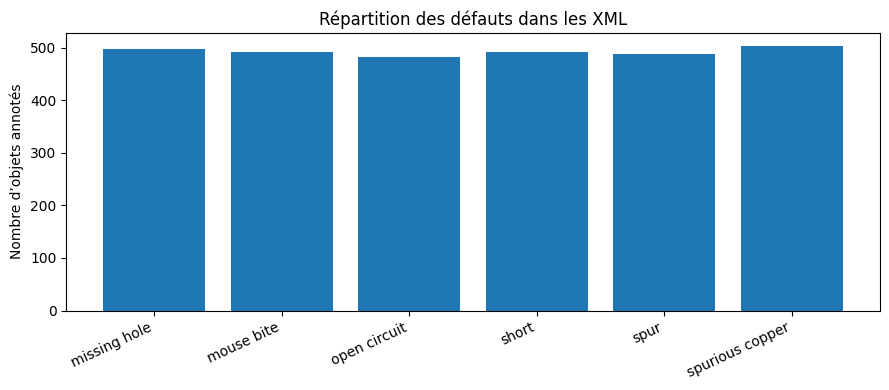

In [5]:
plt.figure(figsize=(9, 4))
plt.bar(CLASS_NAMES, [counts[x] for x in CLASS_NAMES])
plt.xticks(rotation=25, ha='right')
plt.ylabel('Nombre d’objets annotés')
plt.title('Répartition des défauts dans les XML')
plt.tight_layout()
plt.show()

## 4. Associer chaque XML à son image

Je vérifie la correspondance des noms au lieu de prendre une image au hasard. Si plusieurs images peuvent correspondre à une annotation, je marque ce cas comme ambigu et je l'exclus : cela évite une erreur silencieuse d'étiquetage.

In [6]:
image_index = defaultdict(list)
for p in images:
    image_index[p.stem.lower()].append(p)

def get_image_for_xml(xp, root):
    raw = root.findtext('filename', '')
    stem = Path(raw).stem.lower() if raw else xp.stem.lower()
    options = image_index.get(stem, [])
    if not options and stem != xp.stem.lower():
        options = image_index.get(xp.stem.lower(), [])
    if len(options) == 1:
        return options[0]
    if len(options) > 1:
        # Priorité aux images rangées dans un dossier correspondant au XML.
        def common_suffix(a, c):
            aa = [t.lower() for t in a.parent.parts]
            bb = [t.lower() for t in c.parent.parts]
            score = 0
            for x, y in zip(reversed(aa), reversed(bb)):
                if x != y: break
                score += 1
            return score
        scored = sorted(((common_suffix(xp, p), p) for p in options), reverse=True)
        if len(scored) == 1 or scored[0][0] > scored[1][0]:
            return scored[0][1]
    return None

records, issues = [], []
for xp in xml_files:
    try:
        root = ET.parse(xp).getroot()
        ip = get_image_for_xml(xp, root)
        if ip is None:
            issues.append((str(xp), 'image absente ou ambiguë'))
            continue
        with Image.open(ip) as im:
            width, height = im.size
        if not width or not height:
            raise ValueError('dimensions nulles')
        boxes = []
        for obj in root.findall('object'):
            name = normalize_name(obj.findtext('name', ''))
            if name not in CLASS_TO_ID:
                raise ValueError(f'classe inconnue : {name}')
            bb = obj.find('bndbox')
            if bb is None:
                raise ValueError('rectangle manquant')
            x1, y1, x2, y2 = [float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')]
            x1, x2 = sorted((max(0, min(width, x1)), max(0, min(width, x2))))
            y1, y2 = sorted((max(0, min(height, y1)), max(0, min(height, y2))))
            if x2 <= x1 or y2 <= y1:
                raise ValueError('rectangle vide')
            boxes.append((CLASS_TO_ID[name], x1, y1, x2, y2))
        if not boxes:
            issues.append((str(xp), 'aucun objet annoté'))
            continue
        records.append({'image': ip, 'xml': xp, 'width': width,
                        'height': height, 'boxes': boxes})
    except (ValueError, ET.ParseError, OSError, TypeError) as err:
        issues.append((str(xp), str(err)))
print('Images annotées exploitables :', len(records))
print('Problèmes à examiner :', len(issues))
print('Exemples :', issues[:8])
if not records:
    raise RuntimeError('Aucune association image/XML valide. Vérifier les noms et dossiers.')
if len(issues) > len(xml_files) * 0.1:
    raise RuntimeError('Plus de 10 % de XML non appariés : vérifier la structure du dataset.')

Images annotées exploitables : 693
Problèmes à examiner : 0
Exemples : []


## 5. Visualiser quelques annotations

Cette vérification visuelle est indispensable : une bonne conversion numérique n'a pas de sens si les rectangles ne correspondent pas aux défauts visibles.

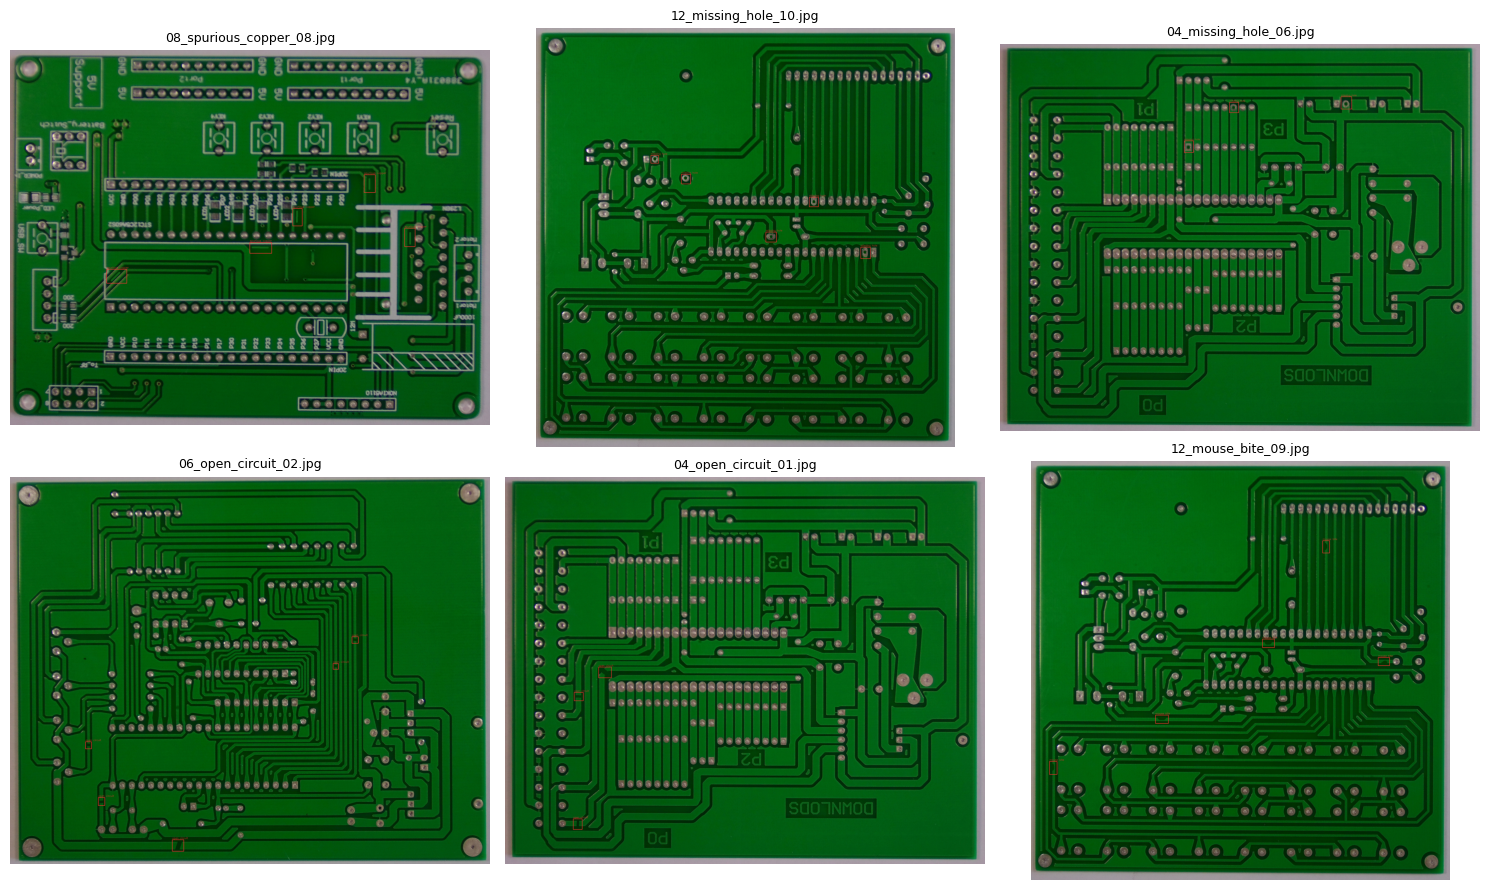

In [7]:
sample = random.sample(records, min(6, len(records)))
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax in axs.flat:
    ax.axis('off')
for ax, item in zip(axs.flat, sample):
    bgr = cv2.imread(str(item['image']))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    for cls, x1, y1, x2, y2 in item['boxes']:
        cv2.rectangle(rgb, (int(x1), int(y1)), (int(x2), int(y2)), (255, 50, 50), 2)
        cv2.putText(rgb, CLASS_NAMES[cls], (int(x1), max(14, int(y1)-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 50, 50), 1)
    ax.imshow(rgb)
    ax.set_title(item['image'].name[:35], fontsize=9)
plt.tight_layout(); plt.show()

## 6. Séparer les données par carte électronique

Le dataset a été construit à partir d'une dizaine de cartes de référence : chaque carte a été photographiée plusieurs fois avec différents défauts ajoutés. Le numéro de carte est le premier nombre du nom de fichier (`01_missing_hole_01.jpg` → carte `01`).

Je place **toutes les photos d'une même carte dans un seul ensemble** : le modèle n'est jamais évalué sur une carte vue pendant l'entraînement. Parmi toutes les répartitions possibles des cartes (environ 60 % / 20 % / 20 %), je garde celle où **chaque type de défaut** est le mieux réparti entre train, validation et test. Je vérifie ensuite qu'aucune classe ne manque dans un ensemble.

In [8]:
def board_id(item):
    # « 01_missing_hole_01.jpg » : le premier nombre identifie la carte.
    m = re.match(r'(\d+)_', item['image'].stem)
    if m is None:
        raise ValueError(f'Numéro de carte introuvable : {item["image"].name}')
    return m.group(1)

def class_counts(rows):
    c = Counter(cls for r in rows for cls, *_ in r['boxes'])
    return np.array([c[i] for i in range(len(CLASS_NAMES))])

boards = defaultdict(list)
for r in records:
    boards[board_id(r)].append(r)
board_ids = sorted(boards)
print('Cartes trouvées :', board_ids)
if len(board_ids) < 3:
    raise RuntimeError('Moins de trois cartes : impossible de faire trois ensembles indépendants.')

# On essaie toutes les répartitions des cartes et on garde la plus équilibrée par classe.
TARGET = {'train': 0.6, 'val': 0.2, 'test': 0.2}
n_held = max(1, round(0.2 * len(board_ids)))
per_board = {b: class_counts(boards[b]) for b in board_ids}
total = class_counts(records)
best = None
for val_b in itertools.combinations(board_ids, n_held):
    rest = [b for b in board_ids if b not in val_b]
    for test_b in itertools.combinations(rest, n_held):
        split_b = {'train': [b for b in rest if b not in test_b],
                   'val': list(val_b), 'test': list(test_b)}
        score = sum(np.abs(sum(per_board[b] for b in bs) / total - TARGET[s]).sum()
                    for s, bs in split_b.items())
        if best is None or score < best[0]:
            best = (score, split_b)
split_boards = best[1]
alloc = {s: [r for b in bs for r in boards[b]] for s, bs in split_boards.items()}

summary = pd.DataFrame({s: class_counts(rows) for s, rows in alloc.items()}, index=CLASS_NAMES)
summary.loc['images'] = [len(rows) for rows in alloc.values()]
for s, bs in split_boards.items():
    print(f'{s:5} : cartes {bs}')
print(summary)
if (summary.drop('images') == 0).any().any():
    raise RuntimeError('Une classe manque dans un ensemble : revoir la répartition des cartes.')
assert sum(map(len, alloc.values())) == len(records)

Cartes trouvées : ['01', '04', '05', '06', '07', '08', '09', '10', '11', '12']
train : cartes ['01', '04', '05', '06', '09', '10']
val   : cartes ['07', '11']
test  : cartes ['08', '12']
                 train  val  test
missing hole       296  100   101
mouse bite         292  100   100
open circuit       281  101   100
short              291  101    99
spur               287  100   101
spurious copper    302  101   100
images             453  120   120


## 7. Convertir les annotations Pascal VOC au format YOLO

Le format YOLO contient : `id_classe centre_x centre_y largeur hauteur` avec des valeurs comprises entre 0 et 1. Je conserve les images originales en couleur ; le redimensionnement sera géré par YOLO au moment de l'entraînement.

In [9]:
OUT = WORK/'pcb_akhatova_yolo'
shutil.rmtree(OUT, ignore_errors=True)  # repartir de zéro si la cellule est relancée
for split in alloc:
    (OUT/'images'/split).mkdir(parents=True, exist_ok=True)
    (OUT/'labels'/split).mkdir(parents=True, exist_ok=True)

for split, rows in alloc.items():
    for r in rows:
        uid = hashlib.sha1(str(r['xml'].relative_to(DATA_ROOT)).encode()).hexdigest()[:12]
        dest_image = OUT/'images'/split/(uid + r['image'].suffix.lower())
        shutil.copy2(r['image'], dest_image)
        lines = []
        for cls, x1, y1, x2, y2 in r['boxes']:
            w, h = r['width'], r['height']
            lines.append(f'{cls} {(x1+x2)/(2*w):.6f} {(y1+y2)/(2*h):.6f} '
                         f'{(x2-x1)/w:.6f} {(y2-y1)/h:.6f}')
        (OUT/'labels'/split/(uid+'.txt')).write_text('\n'.join(lines)+'\n')

configuration = {'path': str(OUT), 'train': 'images/train',
                 'val': 'images/val', 'test': 'images/test',
                 'names': dict(enumerate(CLASS_NAMES))}
(OUT/'data.yaml').write_text(yaml.safe_dump(configuration, sort_keys=False, allow_unicode=True))
print((OUT/'data.yaml').read_text())
print('Nombre d’images converties :', sum(len(v) for v in alloc.values()))

path: /content/pcb_akhatova_yolo
train: images/train
val: images/val
test: images/test
names:
  0: missing hole
  1: mouse bite
  2: open circuit
  3: short
  4: spur
  5: spurious copper

Nombre d’images converties : 693


## 8. Vérifier les fichiers convertis

Je contrôle les bornes des annotations, les identifiants de classes et les correspondances image/étiquette. Une anomalie de conversion peut faire perdre beaucoup de temps pendant l'entraînement.

In [10]:
for split in alloc:
    img_files = list((OUT/'images'/split).iterdir())
    label_files = list((OUT/'labels'/split).glob('*.txt'))
    assert len(img_files) == len(label_files)
    for im in img_files:
        lab = OUT/'labels'/split/(im.stem+'.txt')
        assert lab.exists(), im.name
        for line in lab.read_text().splitlines():
            values = list(map(float, line.split()))
            assert len(values) == 5 and int(values[0]) in range(6)
            assert all(0 <= v <= 1 for v in values[1:]), (lab, line)
print('Vérification des étiquettes terminée.')

Vérification des étiquettes terminée.


## 9. Entraîner un premier modèle YOLO11n

Je commence par la version nano pour disposer d'un modèle de référence rapide. `yolo11n.pt` est pré-entraîné sur un autre jeu de données ; ici je l'adapte aux défauts PCB.

- `imgsz=1280` : les photos font environ 3000 pixels de large et beaucoup de défauts seulement quelques dizaines de pixels. À 640, ils devenaient presque invisibles.
- `patience=0` : pas d'arrêt anticipé. La validation est petite donc bruitée, et l'arrêt anticipé coupait l'entraînement trop tôt. Les 80 époques sont faites, y compris les 10 dernières sans mosaïque (`close_mosaic`), et `best.pt` reste la meilleure époque sur la validation.
- `cache='ram'` : les images redimensionnées sont gardées en mémoire pour accélérer chaque époque.

Durée indicative sur un GPU T4 : environ 1 à 2 heures.

In [11]:
BASE = YOLO('yolo11n.pt')
train_results = BASE.train(
    data=str(OUT/'data.yaml'), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    patience=PATIENCE, cache='ram', seed=SEED, device=DEVICE,
    project=str(RUNS), name='baseline_yolo11n',
    exist_ok=True, plots=True)
BASE_WEIGHTS = RUNS/'baseline_yolo11n'/'weights'/'best.pt'
assert BASE_WEIGHTS.exists(), 'Poids introuvables : vérifier le journal de train.'
print('Poids sélectionnés :', BASE_WEIGHTS)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pcb_akhatova_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo11n, nbs=64, nms=None, opset=None, optimiz

## 10. Lire les courbes d'apprentissage

Les courbes aident à voir si les pertes diminuent et si les métriques de validation progressent. Je regarde surtout le rappel, car un défaut manqué peut être plus problématique qu'une fausse alerte.

 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    76 1490.90         1.18588         0.56505         0.97790               0.98015            0.96415           0.98189              0.52619       1.55710       0.60172       1.27786 0.000072 0.000072 0.000072
    77 1510.06         1.20718         0.57708         0.97786               0.98476            0.95893           0.97953              0.52262       1.56552       0.60754       1.28402 0.000060 0.000060 0.000060
    78 1529.08         1.19614         0.57118         0.98033               0.98527            0.95952           0.97730              0.51601       1.58490       0.61075       1.29742 0.000047 0.000047 0.000047
    79 1547.27         1.17421         0.55436         0.97194               0.98308            0.95907           0.97982              0.51075       1.6

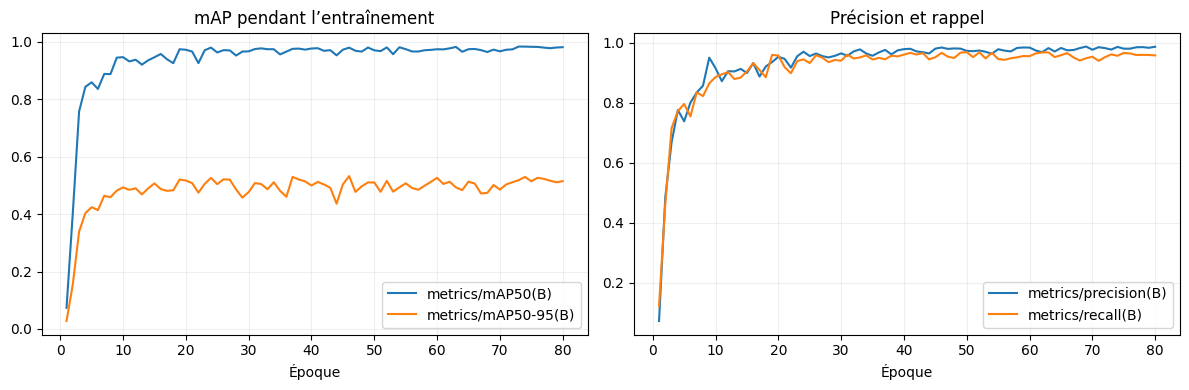

In [12]:
history = pd.read_csv(RUNS/'baseline_yolo11n'/'results.csv')
history.columns = history.columns.str.strip()
print(history.tail(5).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for col in ['metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    if col in history: axs[0].plot(history['epoch'], history[col], label=col)
for col in ['metrics/precision(B)', 'metrics/recall(B)']:
    if col in history: axs[1].plot(history['epoch'], history[col], label=col)
for ax in axs:
    ax.set_xlabel('Époque'); ax.legend(); ax.grid(alpha=0.2)
axs[0].set_title('mAP pendant l’entraînement')
axs[1].set_title('Précision et rappel')
plt.tight_layout(); plt.show()

## 11. Mesurer les performances sur validation

Ce premier bilan sert à comprendre les erreurs, pas à annoncer un résultat final. Je conserve le jeu de test pour la dernière évaluation, une fois les choix de modèle terminés.

Le tableau par classe n'affiche que les classes réellement présentes dans l'ensemble évalué : une classe absente n'a pas de score (YOLO lui attribue sinon la moyenne générale, ce qui donne un faux résultat).

In [13]:
baseline = YOLO(str(BASE_WEIGHTS))
val_metrics = baseline.val(data=str(OUT/'data.yaml'), split='val', imgsz=IMGSZ,
                           plots=True, project=str(RUNS),
                           name='baseline_val', exist_ok=True)

def per_class_table(metrics):
    # Seules les classes présentes dans l'ensemble évalué ont un score réel.
    box = metrics.box
    rows = [{'Classe': CLASS_NAMES[int(c)], 'Précision': box.p[k], 'Rappel': box.r[k],
             'mAP50': box.ap50[k], 'mAP50-95': box.ap[k]}
            for k, c in enumerate(box.ap_class_index)]
    missing = set(CLASS_NAMES) - {r['Classe'] for r in rows}
    if missing:
        print('⚠️ Classes absentes, sans score :', sorted(missing))
    return pd.DataFrame(rows).round(4)

print('Precision :', round(val_metrics.box.mp, 4))
print('Recall    :', round(val_metrics.box.mr, 4))
print('mAP@50    :', round(val_metrics.box.map50, 4))
print('mAP@50:95 :', round(val_metrics.box.map, 4))
display(per_class_table(val_metrics))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1591.2±2106.1 MB/s, size: 994.1 KB)
val: Scanning /content/pcb_akhatova_yolo/labels/val.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 41.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.3s/it 10.1s
                   all        120        603      0.983      0.966      0.979      0.537
          missing hole         20        100      0.986          1      0.995      0.586
            mouse bite         20        100      0.975       0.96      0.981      0.573
          open circuit         20        101       0.99      0.979      0.989      0.565
                 short         20        101       0.98       0.98      0.977      0.475
                  spur         20   

,Classe,Précision,Rappel,mAP50,mAP50-95
0,missing hole,0.9861,1.0000,0.9950,0.5865
1,mouse bite,0.9755,0.9600,0.9810,0.5735
2,open circuit,0.9900,0.9792,0.9891,0.5647
3,short,0.9798,0.9802,0.9766,0.4753
4,spur,0.9787,0.9183,0.9435,0.4534
5,spurious copper,0.9873,0.9604,0.9906,0.5687


## 12. Regarder des prédictions et chercher les erreurs

Les métriques globales ne montrent pas toujours les petits défauts manqués. J'affiche des exemples du jeu de validation et je les compare aux annotations vues au début.

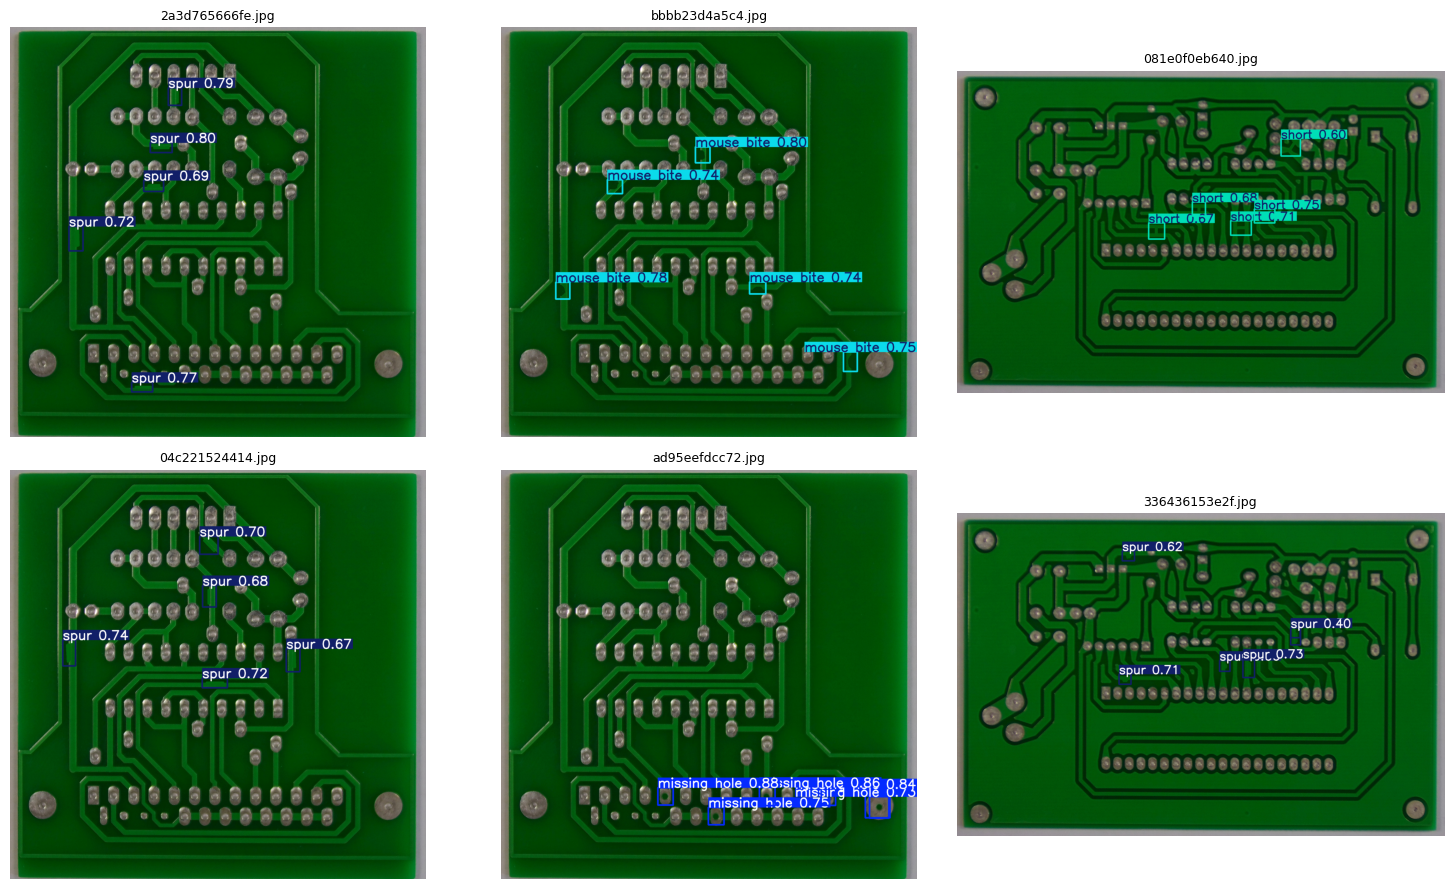

In [14]:
val_images = sorted((OUT/'images'/'val').iterdir())
chosen = random.sample(val_images, min(6, len(val_images)))
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax in axs.flat: ax.axis('off')
for ax, ip in zip(axs.flat, chosen):
    prediction = baseline.predict(str(ip), imgsz=IMGSZ, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(prediction.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(ip.name[:16], fontsize=9)
plt.tight_layout(); plt.show()

## 13. Comparer avec YOLO11s (expérience facultative)

Une architecture plus grande pourrait aider à reconnaître certains petits défauts, mais elle demande davantage de calcul. Je la compare à la baseline sur le **même ensemble de validation**. Si les ressources GPU sont limitées, je peux désactiver cette expérience.

In [15]:
RUN_YOLO11S = False  # passer à True pour lancer la deuxième expérience (environ 2 fois plus long)
if RUN_YOLO11S:
    larger = YOLO('yolo11s.pt')
    larger.train(data=str(OUT/'data.yaml'), epochs=EPOCHS, imgsz=IMGSZ,
                 batch=max(1, BATCH // 2), patience=PATIENCE, cache='ram', seed=SEED,
                 device=DEVICE, project=str(RUNS), name='compare_yolo11s',
                 exist_ok=True, plots=True)
    larger_weights = RUNS/'compare_yolo11s'/'weights'/'best.pt'
    larger_metrics = YOLO(str(larger_weights)).val(
        data=str(OUT/'data.yaml'), split='val', imgsz=IMGSZ, plots=True,
        project=str(RUNS), name='compare_yolo11s_val', exist_ok=True)
    print('YOLO11s mAP50-95 :', larger_metrics.box.map)
else:
    print('Comparaison YOLO11s non exécutée (RUN_YOLO11S=False).')

Comparaison YOLO11s non exécutée (RUN_YOLO11S=False).


## 14. Étudier la robustesse : flou et luminosité

Je crée des copies perturbées **des images de validation seulement**, en conservant les mêmes annotations. Cela permet de tester la sensibilité de YOLO aux conditions d'acquisition. Cette expérience n'est pas utilisée pour entraîner le modèle.

J'ajoute une condition **normale** (images non perturbées) comme référence. Toutes les conditions, y compris la normale, sont réenregistrées en JPEG avec la même qualité : la seule différence entre elles est donc la perturbation. Un écart de mAP inférieur à environ 0,02 peut venir du hasard ; je ne l'interprète pas comme un vrai effet.

In [16]:
ROBUST_ROOT = WORK/'pcb_robustesse'
shutil.rmtree(ROBUST_ROOT, ignore_errors=True)
transformations = {
    'normale': lambda im: im,
    'flou': lambda im: cv2.GaussianBlur(im, (5, 5), 1.2),
    'sombre': lambda im: cv2.convertScaleAbs(im, alpha=0.7, beta=0),
    'clair': lambda im: cv2.convertScaleAbs(im, alpha=1.15, beta=18),
}
for tag, fn in transformations.items():
    img_dir = ROBUST_ROOT/tag/'images'/'val'
    lab_dir = ROBUST_ROOT/tag/'labels'/'val'
    img_dir.mkdir(parents=True, exist_ok=True)
    lab_dir.mkdir(parents=True, exist_ok=True)
    for ip in val_images:
        image = cv2.imread(str(ip))
        cv2.imwrite(str(img_dir/(ip.stem+'.jpg')), fn(image), [cv2.IMWRITE_JPEG_QUALITY, 95])
        shutil.copy2(OUT/'labels'/'val'/(ip.stem+'.txt'), lab_dir/(ip.stem+'.txt'))
print('Copies pour les tests de robustesse créées.')

Copies pour les tests de robustesse créées.


In [17]:
robust_rows = []
for tag in transformations:
    root = ROBUST_ROOT/tag
    data = {'path': str(root), 'train': 'images/val',
            'val': 'images/val', 'test': 'images/val',
            'names': dict(enumerate(CLASS_NAMES))}
    yaml_path = root/'data.yaml'
    yaml_path.write_text(yaml.safe_dump(data, sort_keys=False))
    m = baseline.val(data=str(yaml_path), split='val', imgsz=IMGSZ,
                     project=str(RUNS),
                     name='robust_'+tag, exist_ok=True, plots=False)
    robust_rows.append({'Condition': tag, 'Précision': m.box.mp,
                        'Rappel': m.box.mr, 'mAP50': m.box.map50,
                        'mAP50-95': m.box.map})
robust_table = pd.DataFrame(robust_rows)
reference = robust_table.loc[robust_table['Condition'] == 'normale', 'mAP50'].iloc[0]
robust_table['Écart mAP50 / normale'] = robust_table['mAP50'] - reference
display(robust_table.round(4))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4011.8±547.6 MB/s, size: 1107.6 KB)
val: Scanning /content/pcb_robustesse/normale/labels/val... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 1.7Kit/s 0.1s
val: New cache created: /content/pcb_robustesse/normale/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.3it/s 6.0s
                   all        120        603      0.984      0.969      0.979      0.536
          missing hole         20        100      0.995          1      0.995       0.58
            mouse bite         20        100       0.98      0.967      0.982      0.569
          open circuit         20        101      0.987       0.98       0.99      0.563
                 short         20        101      0.978

,Condition,Précision,Rappel,mAP50,mAP50-95,Écart mAP50 / normale
0,normale,0.9836,0.9688,0.9794,0.5355,0.0000
1,flou,0.9829,0.9695,0.9807,0.5395,0.0013
2,sombre,0.9782,0.9631,0.9750,0.5313,-0.0044
3,clair,0.9836,0.9677,0.9762,0.5253,-0.0032


## 15. Choisir le modèle avant le test final

Je prends la décision à partir des résultats de validation uniquement. Par défaut, je conserve YOLO11n ; je ne choisis YOLO11s que si la comparaison a été exécutée et qu'elle donne une amélioration utile.

In [18]:
FINAL_WEIGHTS = BASE_WEIGHTS
if RUN_YOLO11S:
    if larger_metrics.box.map > val_metrics.box.map:
        FINAL_WEIGHTS = larger_weights
print('Modèle retenu avant le test :', FINAL_WEIGHTS)

Modèle retenu avant le test : /content/pcb_runs/baseline_yolo11n/weights/best.pt


## 16. Évaluation finale sur les images de test

Le test est conservé à l'écart du choix des paramètres. Ses scores représentent l'évaluation finale **sur le dataset Akhatova** : ils ne prouvent pas une efficacité industrielle sur des défauts physiques réels.

In [19]:
final_model = YOLO(str(FINAL_WEIGHTS))
test_metrics = final_model.val(
    data=str(OUT/'data.yaml'), split='test', imgsz=IMGSZ, plots=True,
    project=str(RUNS), name='test_final', exist_ok=True)
final_results = {
    'modele': FINAL_WEIGHTS.parent.parent.name,
    'precision': float(test_metrics.box.mp),
    'recall': float(test_metrics.box.mr),
    'mAP50': float(test_metrics.box.map50),
    'mAP50_95': float(test_metrics.box.map),
}
print(pd.Series(final_results))
display(per_class_table(test_metrics))
pd.DataFrame([final_results]).to_csv(WORK/'bilan_pcb.csv', index=False)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 179.8±22.8 MB/s, size: 1450.6 KB)
val: Scanning /content/pcb_akhatova_yolo/labels/test... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 311.3it/s 0.4s
val: New cache created: /content/pcb_akhatova_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.5s/it 12.1s
                   all        120        601       0.91      0.914      0.905      0.469
          missing hole         20        101      0.992          1      0.995      0.576
            mouse bite         20        100      0.927      0.886      0.907      0.405
          open circuit         20        100      0.989      0.908      0.968      0.542
                 short         20         99      0.958       0

,Classe,Précision,Rappel,mAP50,mAP50-95
0,missing hole,0.9925,1.0000,0.9950,0.5759
1,mouse bite,0.9268,0.8865,0.9069,0.4049
2,open circuit,0.9891,0.9082,0.9684,0.5417
3,short,0.9580,0.9596,0.9487,0.4230
4,spur,0.9876,0.7873,0.9475,0.5267
5,spurious copper,0.6055,0.9400,0.6643,0.3409


## 17. Tester le modèle sur quelques autres images

La prédiction ci-dessous ne modifie pas le modèle. Elle sert à visualiser les boîtes, les classes et les scores de confiance. Pour des images externes, il faudrait aussi des annotations fiables afin de mesurer les vrais défauts manqués.

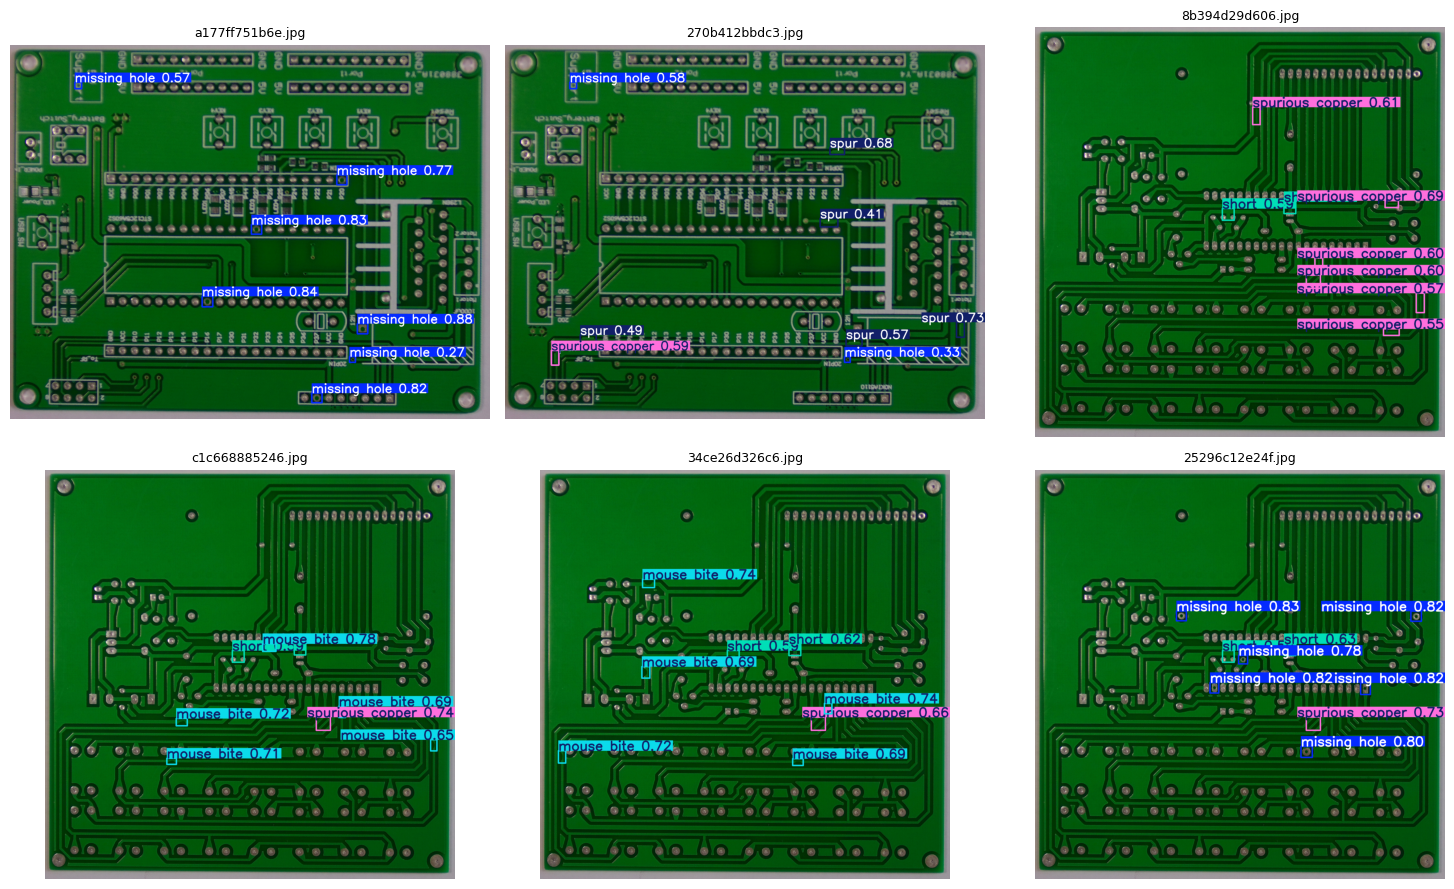

In [20]:
test_images = sorted((OUT/'images'/'test').iterdir())
selected = random.sample(test_images, min(6, len(test_images)))
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax in axs.flat: ax.axis('off')
for ax, ip in zip(axs.flat, selected):
    out = final_model.predict(str(ip), conf=0.25, imgsz=IMGSZ, verbose=False)[0]
    ax.imshow(cv2.cvtColor(out.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(ip.name[:16], fontsize=9)
plt.tight_layout(); plt.show()

## 18. Bilan de l'expérience et conclusion à compléter

**Ce que j'ai réalisé :** préparation et vérification d'un dataset de PCB, conversion des annotations, entraînement supervisé avec YOLO11, évaluation sur des images séparées et tests de sensibilité aux perturbations.

**Observations à écrire après exécution :**

- Sur la validation, la classe la plus difficile était : **[à compléter d'après les métriques et les images]**.
- Le modèle final obtenu était : **[YOLO11n ou YOLO11s]**.
- Sur le test final, la mAP@50 était **[à compléter]** et le rappel **[à compléter]**.
- Avec du flou, les performances **[ont diminué / sont restées proches — à justifier]**.
- Les erreurs les plus fréquentes concernaient **[à compléter à partir d'exemples]**.

**Limites :** les défauts sont synthétiques ; certains types de cartes et certaines conditions de prise de vue peuvent ne pas être représentés. La séparation est faite par numéro de carte, lu dans le nom de fichier. Avec une dizaine de cartes seulement, le test ne contient que deux cartes : les scores restent sensibles à ce choix. Une validation supplémentaire sur de véritables défauts industriels serait nécessaire avant toute application réelle.

**Perspective :** tester le modèle sur un petit ensemble de cartes nouvelles annotées, puis essayer un fine-tuning si les résultats montrent un changement important de domaine.

### Références

1. Akhatova, *PCB Defects*, Kaggle : https://www.kaggle.com/datasets/akhatova/pcb-defects
2. Huang & Wei, *A PCB Dataset for Defects Detection and Classification* (2019).
3. Documentation Ultralytics YOLO : https://docs.ultralytics.com/usage/python/

*Les résultats chiffrés et les observations doivent être ajoutés uniquement après l'exécution des cellules.*